# Compare Guitar-TECHS labels with recorded audio
We are inspecting an externally labeled recording, not training a model.
First overlay the supplied MIDI labels on the waveform; then compare our
autocorrelation estimates with the labels. A label and a prediction are different
sources of information. We do not shift the labels to make them look correct.

Run from the project folder using Guitar ML (.venv). Mido reads MIDI files;
install it with `.venv/bin/python -m pip install mido` if needed.
The helper `guitartechs_midi.py` handles event ordering, tempo conversion, and
note-on/off pairing. The audio and comparison calculations are visible here.

## 1. Read a short part of the WAV
The original P1 file is 552 seconds long. Read only 0–11.9 seconds, which
includes the first three complete labeled notes, stopping before the fourth.
These boundaries select an excerpt; they are not detected note boundaries.
The dataset stays in Downloads. Change `dataset_folder` if you move it.


In [1]:
from pathlib import Path
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from guitartechs_midi import read_note_labels

dataset_folder = Path.home() / "Downloads/P1_singlenotes"
audio_path = dataset_folder / "audio/directinput/directinput_allsinglenotes.wav"
midi_path = dataset_folder / "midi/midi_allsinglenotes.mid"
excerpt_start_seconds = 0.0
excerpt_stop_seconds = 11.9

audio_info = sf.info(audio_path)
sample_rate = audio_info.samplerate
excerpt_start_sample = round(excerpt_start_seconds * sample_rate)
excerpt_stop_sample = round(excerpt_stop_seconds * sample_rate)
if not 0 <= excerpt_start_sample < excerpt_stop_sample <= audio_info.frames:
    raise ValueError("Choose an excerpt entirely inside the WAV.")
samples, sample_rate = sf.read(audio_path, start=excerpt_start_sample, stop=excerpt_stop_sample)
signal = samples[:, 0] if samples.ndim == 2 else samples
if not np.all(np.isfinite(signal)):
    raise ValueError("Audio contains nonfinite samples.")
original_time = (excerpt_start_sample + np.arange(len(signal))) / sample_rate
print(f"{audio_path.name}: {sample_rate:,} Hz, {audio_info.channels} channel(s)")
print(f"Original file samples [{excerpt_start_sample}:{excerpt_stop_sample}] (stop excluded)")
print(f"Loaded {len(signal) / sample_rate:.3f} seconds; original WAV is {audio_info.duration:.1f} seconds")


directinput_allsinglenotes.wav: 48,000 Hz, 1 channel(s)
Original file samples [0:571200] (stop excluded)
Loaded 11.900 seconds; original WAV is 552.0 seconds


## 2. Turn MIDI events into a readable label table
MIDI stores instructions such as "note 40 starts" and "note 40 ends", not an
audio waveform. In the octave naming used here, MIDI 40 is E2 and MIDI 60 is C4.
Pitch names in other software may use different octave numbering.

MIDI timing is in **ticks**, not audio samples. This file has 960 ticks per
quarter note and a tempo of 1,000,000 microseconds per quarter (one second).
Thus one tick is 1/960 seconds. The reader also handles tempo changes.
Track names identify the strings; MIDI channels alone do not identify P1's strings.

Label frequency = 440 * 2 ** ((MIDI note - 69) / 12): note 69 is A4 at 440 Hz,
each semitone multiplies frequency by 2 ** (1/12), and 12 semitones double it.
This gives a nominal equal-tempered target, not a measurement of actual tuning.
Fret = MIDI pitch minus that string's open MIDI pitch, assuming standard tuning.


In [2]:
all_labels, midi_metadata = read_note_labels(midi_path)
labels = [note for note in all_labels
          if note["end_seconds"] > excerpt_start_sample / sample_rate
          and note["start_seconds"] < excerpt_stop_sample / sample_rate]
if not labels:
    raise ValueError("No MIDI note labels overlap this excerpt.")
pitch_names = ("C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B")
open_string_midi = {"E": 40, "A": 45, "D": 50, "G": 55, "B": 59, "e": 64}
for note in labels:
    pitch = note["midi_note"]
    note["name"] = f"{pitch_names[pitch % 12]}{pitch // 12 - 1}"
    note["label_hz"] = 440 * 2 ** ((pitch - 69) / 12)
    open_pitch = open_string_midi.get(note["string_track"])
    note["fret"] = pitch - open_pitch if open_pitch is not None else "?"

print("Ticks per quarter:", midi_metadata["ticks_per_quarter"])
print("Tempo events (seconds, microseconds/quarter):", midi_metadata["tempo_events"])
print("\nSUPPLIED LABELS — times refer to the original file")
print("Note  MIDI  String  Fret   Start(s)   End(s)   Nominal Hz")
for note in labels:
    print(f"{note['name']:4}  {note['midi_note']:4}  {note['string_track']:>6}  "
          f"{str(note['fret']):>4}  {note['start_seconds']:9.4f}  "
          f"{note['end_seconds']:7.4f}  {note['label_hz']:11.2f}")


Ticks per quarter: 960
Tempo events (seconds, microseconds/quarter): [(0.0, 1000000)]

SUPPLIED LABELS — times refer to the original file
Note  MIDI  String  Fret   Start(s)   End(s)   Nominal Hz
E2      40       E     0     0.0000   3.7354        82.41
F2      41       E     1     4.0208   7.8000        87.31
F#2     42       E     2     8.0260  11.7906        92.50


## 3. Overlay the supplied labels on the waveform
Shaded bands cover the MIDI note-on to note-off intervals. Dashed lines mark
label starts. They are supplied annotations, not automatically detected attacks.
The lower panel magnifies the second label's start (250 ms on either side).
This helps inspect timing without declaring an exact audio onset from a plot.

The publisher warns of possible signal misalignment up to 100 ms. We apply no
correction here. MIDI note-off also need not coincide with the final audible
decay. The first label begins at file time zero, so it has no preceding context.


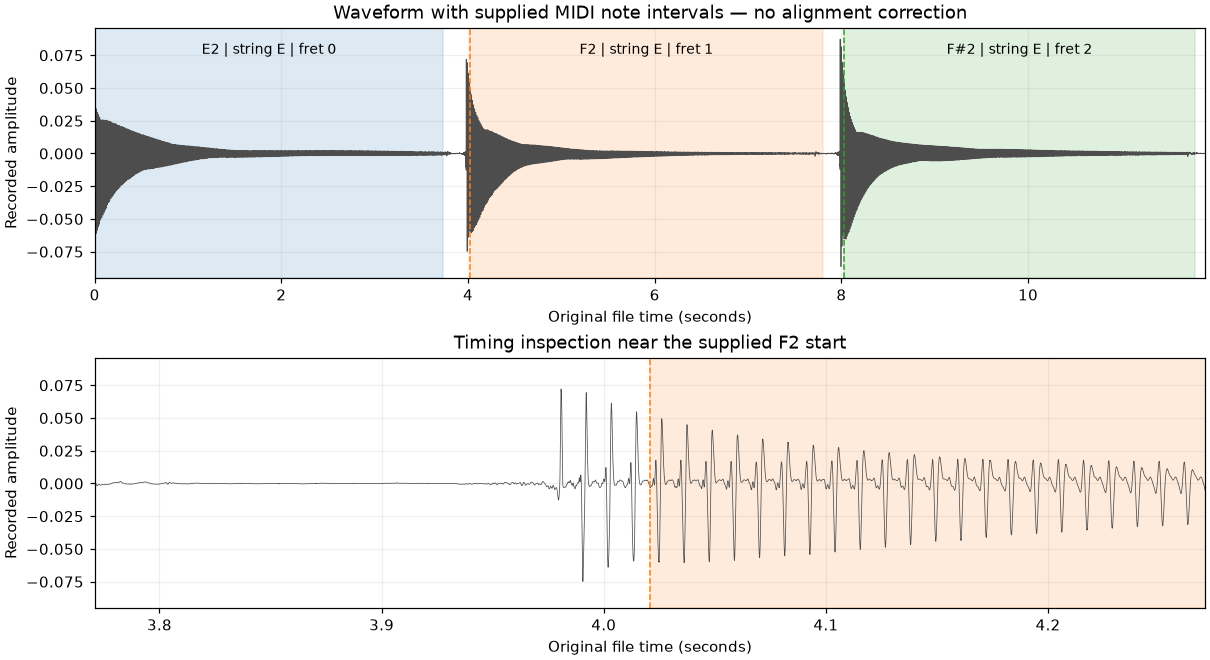

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), constrained_layout=True)
colors = plt.get_cmap("tab10")
for ax in axes:
    ax.plot(original_time, signal, color="0.3", linewidth=0.5, label="Recorded amplitude")
    for index, note in enumerate(labels):
        ax.axvspan(note["start_seconds"], note["end_seconds"], color=colors(index % 10), alpha=0.15)
        ax.axvline(note["start_seconds"], color=colors(index % 10), linestyle="--", linewidth=1)
    ax.set(xlabel="Original file time (seconds)", ylabel="Recorded amplitude")
    ax.grid(alpha=0.2)
axes[0].set(xlim=(excerpt_start_sample / sample_rate, excerpt_stop_sample / sample_rate),
            title="Waveform with supplied MIDI note intervals — no alignment correction")
for index, note in enumerate(labels):
    midpoint = (max(note["start_seconds"], excerpt_start_sample / sample_rate)
                + min(note["end_seconds"], excerpt_stop_sample / sample_rate)) / 2
    axes[0].text(midpoint, 0.94, f"{note['name']} | string {note['string_track']} | fret {note['fret']}",
                 transform=axes[0].get_xaxis_transform(), ha="center", va="top", fontsize=9)
review_note = labels[min(1, len(labels) - 1)]
axes[1].set(xlim=(max(excerpt_start_sample / sample_rate, review_note["start_seconds"] - 0.25),
                     min(excerpt_stop_sample / sample_rate, review_note["start_seconds"] + 0.25)),
            title=f"Timing inspection near the supplied {review_note['name']} start")
plt.show()


## 4. Compare one ringing window per label with our estimate
This is **label-guided sampling**, not automatic transcription. For each label,
take 0.5 seconds beginning 0.5 seconds after its supplied start, avoiding the
initial attack. Skip labels without room for that complete window. The provided
pitch does NOT select a lag or restrict its search: the range stays 60–1,000 Hz.
This range covers this excerpt, but not all high notes in the full dataset.

The imported function packages the same centered, zero-lag-normalized
calculation from notebook 02. Its short implementation is in `pitch_analysis.py`,
shared with the sliding-window lesson so these experiments use the same rule.
It returns a candidate frequency, lag, and similarity. There is still no
noise-versus-note decision, and high similarity does not guarantee correct pitch.


In [4]:
from pitch_analysis import estimate_period

offset_after_label = 0.5
analysis_duration = 0.5
comparisons = []
print("Label  Target Hz  Estimated Hz   Lag   Similarity   Original sample interval")
for note in labels:
    first = round((note["start_seconds"] + offset_after_label) * sample_rate)
    last = first + round(analysis_duration * sample_rate)
    if first < excerpt_start_sample or last > min(excerpt_stop_sample, int(np.floor(note["end_seconds"] * sample_rate))):
        print(f"Skipping {note['name']}: complete analysis window is outside the label/excerpt.")
        continue
    window_samples = signal[first - excerpt_start_sample:last - excerpt_start_sample]
    estimated_hz, lag, score = estimate_period(window_samples, sample_rate)
    comparisons.append(dict(note=note, estimated_hz=estimated_hz, lag=lag, score=score,
                            first_sample=first, last_sample=last))
    print(f"{note['name']:5}  {note['label_hz']:9.2f}  {estimated_hz:12.2f}  {lag:4d}  "
          f"{score:11.3f}   [{first}:{last}]")


Label  Target Hz  Estimated Hz   Lag   Similarity   Original sample interval
E2         82.41         82.62   581        0.971   [24000:48000]
F2         87.31         87.75   547        0.970   [217000:241000]
F#2        92.50         93.02   516        0.974   [409250:433250]


## 5. Keep supplied pitch labels separate from our predictions
Blue lines are nominal MIDI frequencies across their labeled intervals.
Orange markers are our estimates; their horizontal bars show exactly which
half-second windows were analyzed. Those bars are NOT uncertainty intervals.
This does not estimate note starts or ends, or show pitch throughout each note.
We have only checked one stable segment per label; it is not a training score.


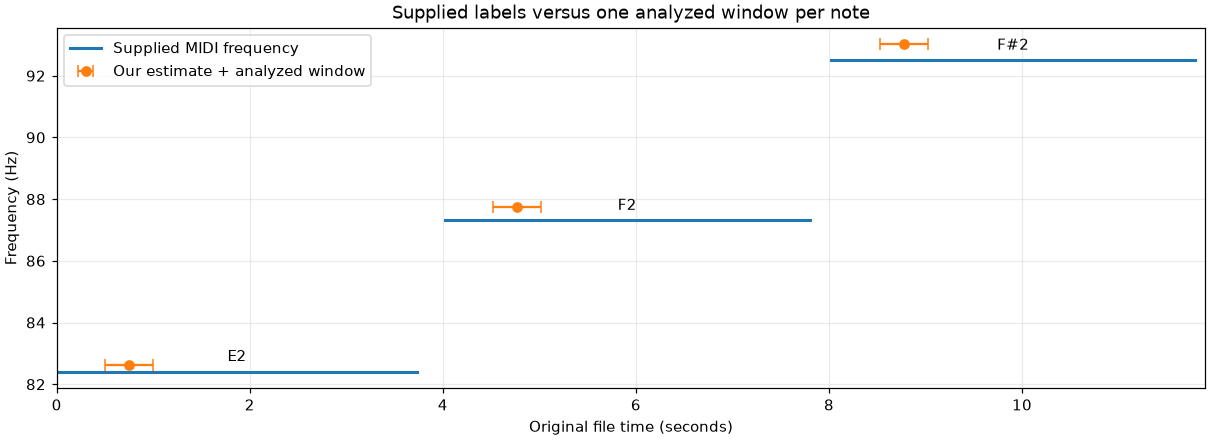

In [5]:
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
for index, note in enumerate(labels):
    left = max(note["start_seconds"], excerpt_start_sample / sample_rate)
    right = min(note["end_seconds"], excerpt_stop_sample / sample_rate)
    ax.plot([left, right], [note["label_hz"]] * 2, color="tab:blue", linewidth=2,
             label="Supplied MIDI frequency" if index == 0 else None)
    ax.annotate(note["name"], ((left + right) / 2, note["label_hz"]),
                 xytext=(0, 7), textcoords="offset points", ha="center")
for index, row in enumerate(comparisons):
    midpoint = (row["first_sample"] + row["last_sample"]) / (2 * sample_rate)
    half_duration = (row["last_sample"] - row["first_sample"]) / (2 * sample_rate)
    ax.errorbar(midpoint, row["estimated_hz"], xerr=half_duration, fmt="o", color="tab:orange",
                 capsize=4, label="Our estimate + analyzed window" if index == 0 else None)
ax.set(xlim=(excerpt_start_sample / sample_rate, excerpt_stop_sample / sample_rate),
       xlabel="Original file time (seconds)", ylabel="Frequency (Hz)",
       title="Supplied labels versus one analyzed window per note")
ax.legend()
ax.grid(alpha=0.25)
plt.show()


Next checkpoint: inspect the label table, waveform timing, and pitch comparison.
We have not validated labels throughout this dataset or aligned its audio/MIDI.
In this excerpt, the second note's visible attack precedes its MIDI start by
roughly a few tens of milliseconds. Leave that discrepancy visible for review.
Estimates are slightly above nominal label frequencies; actual tuning, changing
pitch, and integer-lag estimation can all contribute. We have not separated them.
A later sliding-window experiment can examine transitions and unlabeled gaps.
Do not automatically treat a label gap as acoustic silence: strings may ring out.

Source: [Guitar-TECHS, Pedroza et al., ICASSP 2025](https://zenodo.org/records/14963133).
[Project site](https://guitar-techs.github.io/) specifies CC BY 4.0.
[Mido timing documentation](https://mido.readthedocs.io/en/stable/files/midi.html).
Dataset recordings remain in Downloads; no external audio is copied into Git.
